In [1]:
import torch
import torch.nn as nn
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, ControlNetModel
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import pandas as pd
from torchvision import transforms
import nibabel as nib
from tqdm.auto import tqdm

# --- ローカルGPUの設定 ---
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

/home/masaki/anaconda3/envs/mystudy/lib/python3.9/site-packages/accelerate/utils/torch_xla.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Using device: cuda


In [2]:
# ===================================================================
# 学習時と全く同じモデルクラスを再定義
# ===================================================================
class CustomConditionalLDM(nn.Module):
    # (02_model_training.ipynbで使った【最終決定版】のクラス定義をここにコピー＆ペースト)
    def __init__(self, pretrained_model_name="runwayml/stable-diffusion-v1-5"):
        super().__init__()
        self.vae = AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae")
        self.tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
        self.text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder")
        self.unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet")
        self.scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
        self.controlnet = ControlNetModel.from_config(self.unet.config)
        
        in_channels = 4
        out_channels = self.controlnet.conv_in.out_channels
        self.controlnet.controlnet_cond_embedding = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        )
        for module in self.controlnet.controlnet_cond_embedding.modules():
            if isinstance(module, nn.Conv2d):
                torch.nn.init.zeros_(module.weight)
                torch.nn.init.zeros_(module.bias)

        self.vae.requires_grad_(False)
        self.text_encoder.requires_grad_(False)
        self.unet.requires_grad_(False)

# ===================================================================
# モデルのインスタンス化と重みの読み込み
# ===================================================================
print("Initializing the model structure...")
model = CustomConditionalLDM().to(device)

# --- ★★★ ここが最重要 ★★★ ---
# 学習したControlNetの「最高の重み」を読み込む
CONTROLNET_WEIGHTS_PATH = '/home/masaki/mystudy/trained_models_l+c_150/best_model_epoch_124.pth'
model.controlnet.load_state_dict(torch.load(CONTROLNET_WEIGHTS_PATH, map_location=device))
model.eval() # モデルを推論モードに設定

print(f"✅ Best model weights loaded from: {CONTROLNET_WEIGHTS_PATH}")

Initializing the model structure...
✅ Best model weights loaded from: /home/masaki/mystudy/trained_models/best_model_epoch_124.pth


In [3]:
# --- データセットクラスも再定義が必要 ---
class BrainMetsDataset(Dataset):
    def __init__(self, csv_file, image_root_dir, patient_ids, mode, image_size=256):
        self.data = pd.read_csv(csv_file)
        self.data = self.data[self.data['PatientID'].isin(patient_ids)]
        self.image_root_dir = image_root_dir
        self.mode = mode
        self.scans = self._get_scans()
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((image_size, image_size), antialias=True),
            transforms.Normalize([0.5], [0.5])
        ])
    def _get_scans(self):
        scans = []
        baseline_scans = self.data[self.data['FinalPattern'] == 'Baseline']
        for _, baseline_row in baseline_scans.iterrows():
            scans.append(baseline_row.to_dict())
        print(f"Found {len(scans)} baseline images for '{self.mode}' set.")
        return scans
    def __len__(self):
        return len(self.scans)
    def __getitem__(self, idx):
        scan_info = self.scans[idx]
        base_name_without_ext = scan_info['FileName'].replace('.nii.gz', '')
        filename_with_suffix = f"{base_name_without_ext}_0000.nii.gz"
        path = os.path.join(self.image_root_dir, filename_with_suffix)
        
        try:
            nii_img = nib.load(path)
            data = nii_img.get_fdata().astype('float32')
            slice_img = data[:, :, data.shape[2] // 2]

            if slice_img.max() > slice_img.min():
                slice_img = (slice_img - slice_img.min()) / (slice_img.max() - slice_img.min())
            
            image = self.transform(slice_img).repeat(3, 1, 1)
            
            return {"baseline_image": image, "patient_id": scan_info['PatientID'], "filename": scan_info['FileName']}
        except FileNotFoundError:
            return self.__getitem__((idx + 1) % len(self))

# --- テスト用の患者IDを再生成 ---
IMAGE_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'
CSV_FILE = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
full_df = pd.read_csv(CSV_FILE)
patient_ids = full_df['PatientID'].unique()
_, temp_patient_ids = train_test_split(patient_ids, test_size=0.3, random_state=42)
_, test_patient_ids = train_test_split(temp_patient_ids, test_size=0.5, random_state=42)

# --- テストデータローダーを作成 ---
test_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=test_patient_ids, mode='test')
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

# --- テストデータを1つランダムに取得 ---
sample_batch = next(iter(test_dataloader))
baseline_image = sample_batch["baseline_image"].to(device)
patient_id = sample_batch["patient_id"][0]
baseline_filename = sample_batch["filename"][0]

print(f"\nLoaded baseline image for patient: {patient_id} (File: {baseline_filename})")

Found 205 baseline images for 'test' set.

Loaded baseline image for patient: YG_2JKYOFLC5W1F (File: YG_2JKYOFLC5W1F_2014-06-21_07-57-20.nii.gz)



Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


✅ Segmentation mask loaded for visualization.


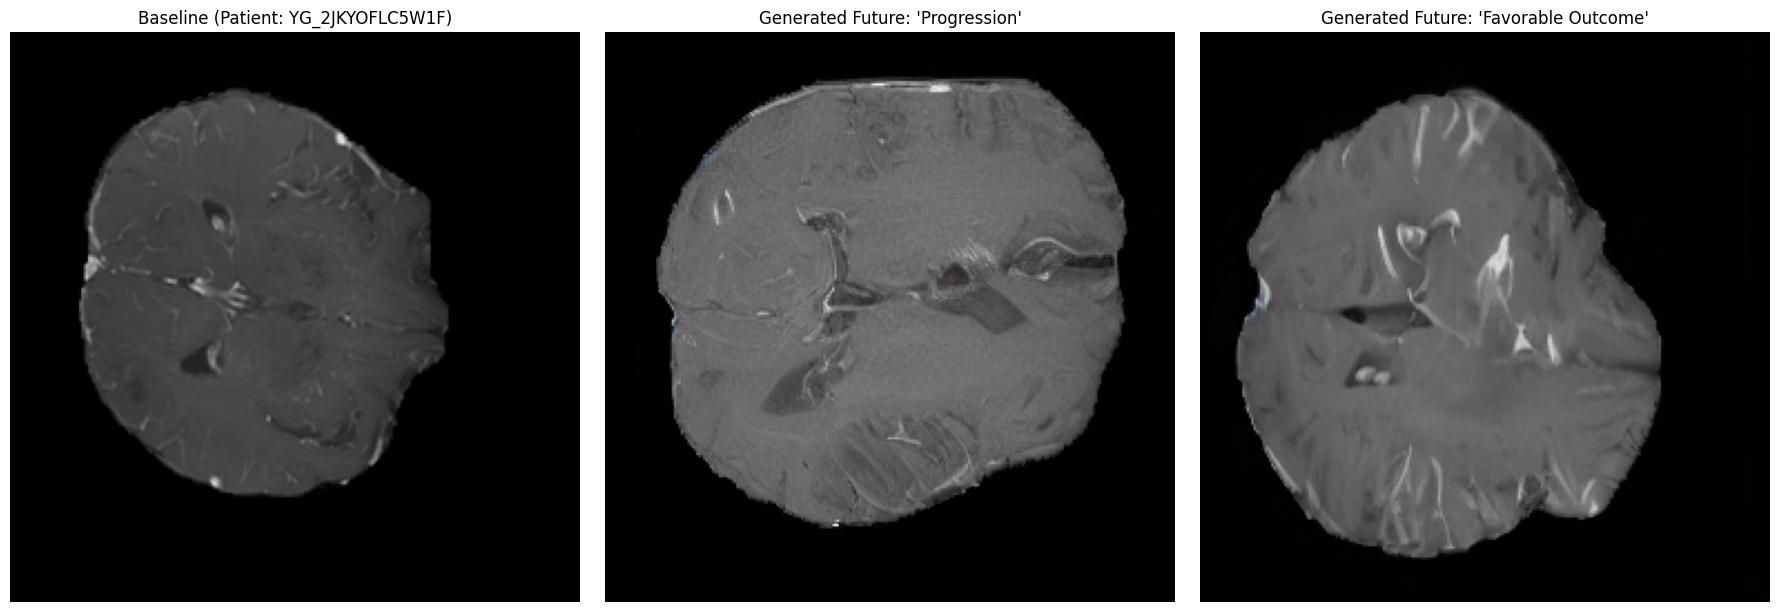

In [4]:
# ===================================================================
# 推論（画像生成）を行う関数
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50):
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    
    with torch.no_grad():
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    model.scheduler.set_timesteps(num_inference_steps)
    latents = torch.randn_like(baseline_latents)

    for t in tqdm(model.scheduler.timesteps, desc="Denoising"):
        with torch.no_grad():
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    with torch.no_grad():
        latents = 1 / model.vae.config.scaling_factor * latents
        image = model.vae.decode(latents).sample
        
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# --- 2つの条件で画像を生成 ---
progression_image = generate_future_image(model, baseline_image, "Progression")
favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")

# ===================================================================
# 結果の可視化（セグメンテーションマスクを重ねて表示）
# ===================================================================
# --- 1. 対応するセグメンテーションマスクを読み込む ---
SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
seg_path = os.path.join(SEG_DIR, baseline_filename)

seg_mask_rgba = None
try:
    seg_nii = nib.load(seg_path)
    seg_data = seg_nii.get_fdata().astype('float32')
    seg_slice = seg_data[:, :, seg_data.shape[2] // 2]
    seg_slice_pil = Image.fromarray(seg_slice).resize((256, 256), Image.NEAREST)
    seg_mask = np.array(seg_slice_pil)
    seg_mask_rgba = np.zeros((256, 256, 4))
    seg_mask_rgba[seg_mask > 0] = [1, 0, 0, 0.4] # 赤色, 40%の透明度
    print("\n✅ Segmentation mask loaded for visualization.")
except FileNotFoundError:
    print(f"\n⚠️ Warning: Segmentation mask not found at {seg_path}")

# --- 2. 3枚の画像を並べて表示 ---
def to_pil(tensor_image):
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

plt.figure(figsize=(18, 6))

# --- ベースライン + マスク ---
plt.subplot(1, 3, 1)
plt.imshow(to_pil(baseline_image), cmap='gray')
if seg_mask_rgba is not None:
    plt.imshow(seg_mask_rgba)
plt.title(f"Baseline (Patient: {patient_id})")
plt.axis('off')

# --- Progression ---
plt.subplot(1, 3, 2)
plt.imshow(progression_image, cmap='gray')
plt.title("Generated Future: 'Progression'")
plt.axis('off')

# --- Favorable Outcome ---
plt.subplot(1, 3, 3)
plt.imshow(favorable_image, cmap='gray')
plt.title("Generated Future: 'Favorable Outcome'")
plt.axis('off')

plt.tight_layout()
plt.show()


--- Processing sample 1/3 for patient: YG_9TT888DM37SZ ---

Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]

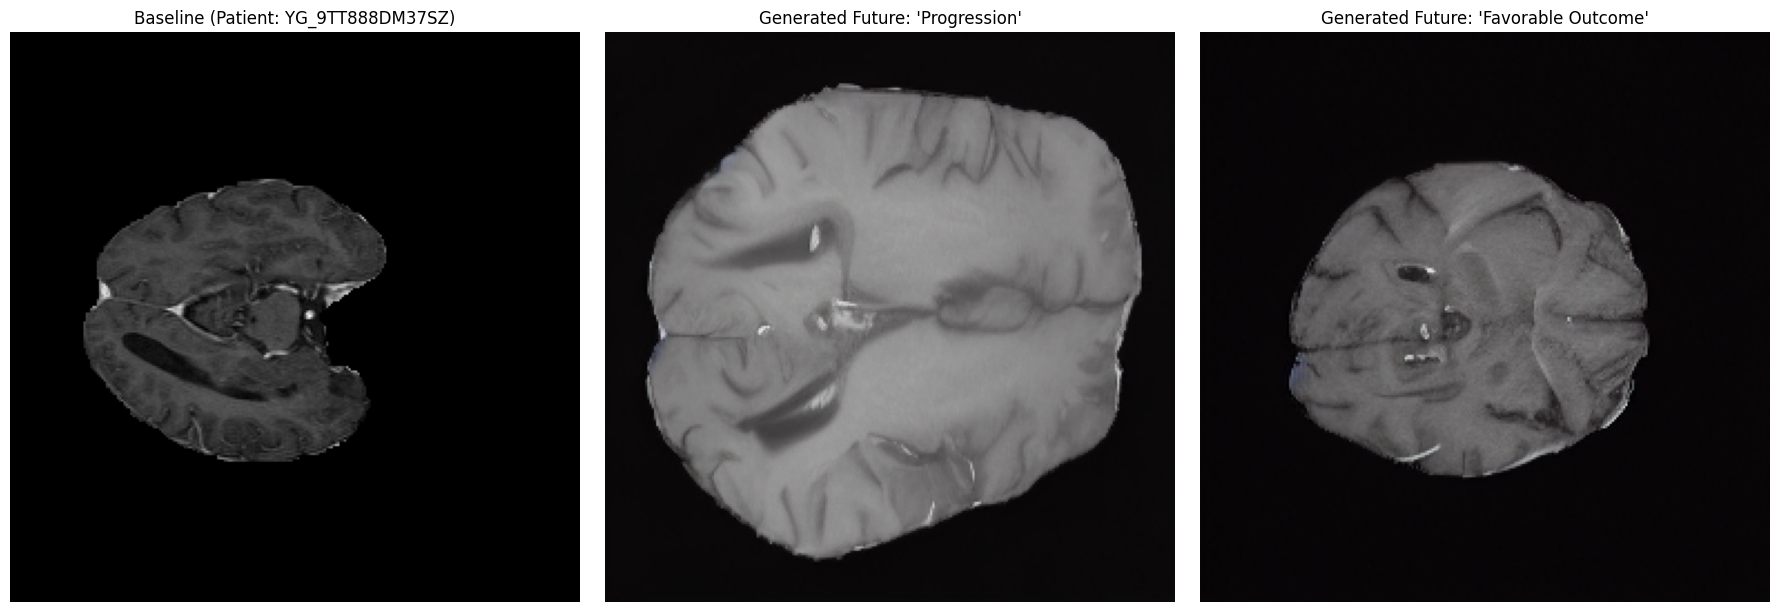


--- Processing sample 2/3 for patient: YG_J7TDRWNCQ0HR ---

Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]

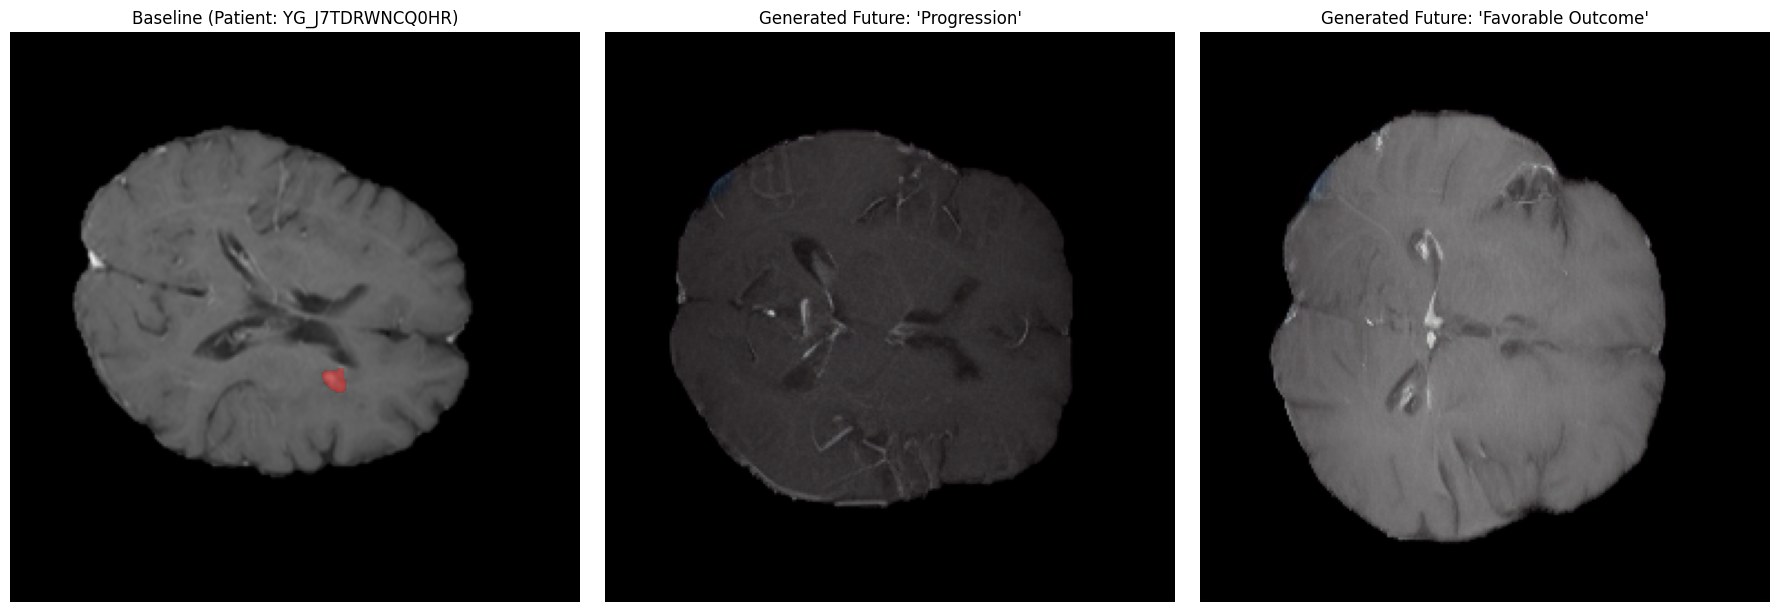


--- Processing sample 3/3 for patient: YG_4Y0TH8T0ERLU ---

Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]

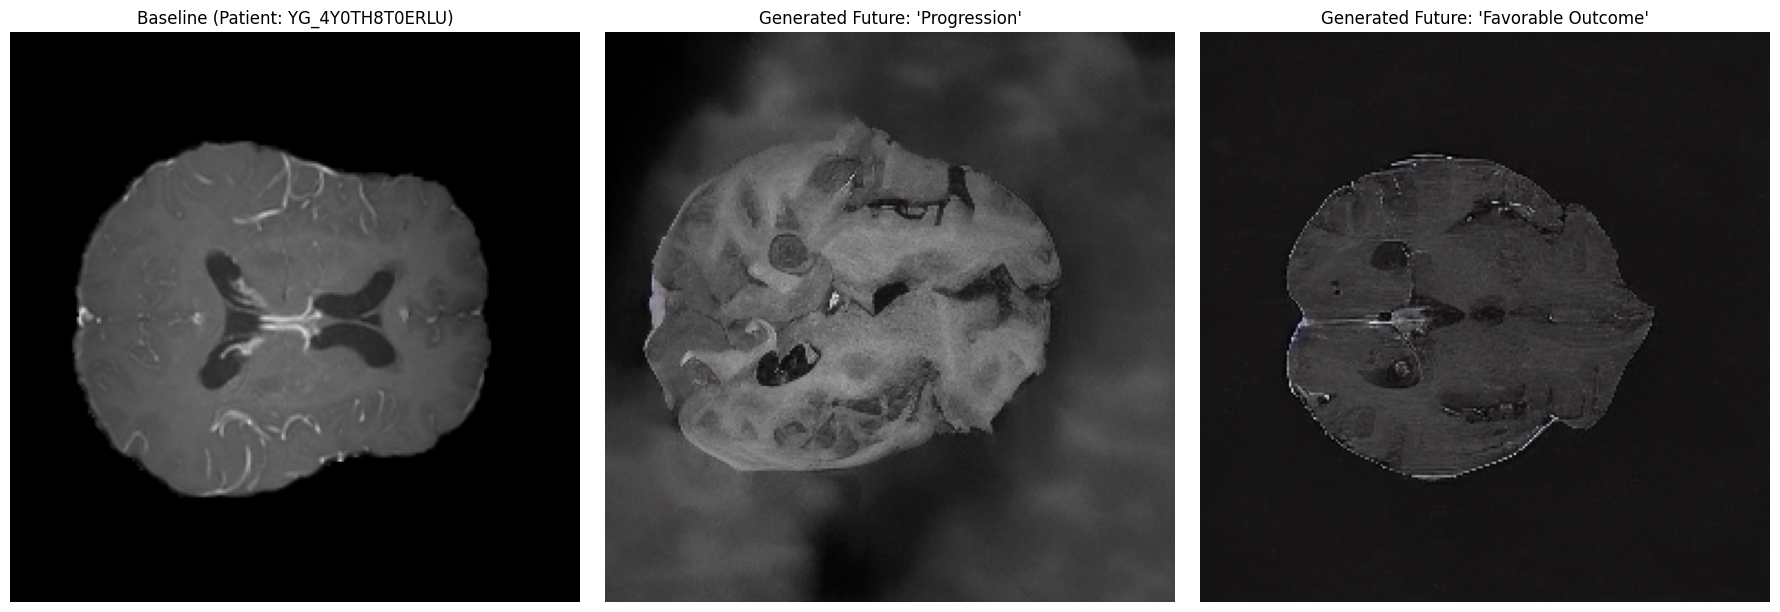

In [5]:
from tqdm.auto import tqdm
from PIL import Image
import numpy as np

# ===================================================================
# 推論（画像生成）を行う関数（変更なし）
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50):
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    with torch.no_grad():
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    model.scheduler.set_timesteps(num_inference_steps)
    latents = torch.randn_like(baseline_latents)

    for t in tqdm(model.scheduler.timesteps, desc="Denoising"):
        with torch.no_grad():
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    with torch.no_grad():
        latents = 1 / model.vae.config.scaling_factor * latents
        image = model.vae.decode(latents).sample
        
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# ===================================================================
# 複数の患者に対してループ処理で生成と可視化を行う
# ===================================================================
NUM_SAMPLES_TO_SHOW = 3 # 表示したい患者の人数

def to_pil(tensor_image):
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

# test_dataloaderから指定した人数分のデータを取得
for i, sample_batch in enumerate(test_dataloader):
    if i >= NUM_SAMPLES_TO_SHOW:
        break

    # --- データを準備 ---
    baseline_image = sample_batch["baseline_image"].to(device)
    patient_id = sample_batch["patient_id"][0]
    baseline_filename = sample_batch["filename"][0]
    print(f"\n--- Processing sample {i+1}/{NUM_SAMPLES_TO_SHOW} for patient: {patient_id} ---")

    # --- 2つの条件で画像を生成 ---
    progression_image = generate_future_image(model, baseline_image, "Progression")
    favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")
    
    # --- 対応するセグメンテーションマスクを読み込む ---
    SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
    seg_path = os.path.join(SEG_DIR, baseline_filename)
    seg_mask_rgba = None
    try:
        seg_nii = nib.load(seg_path)
        seg_data = seg_nii.get_fdata().astype('float32')
        seg_slice = seg_data[:, :, seg_data.shape[2] // 2]
        seg_slice_pil = Image.fromarray(seg_slice).resize((256, 256), Image.NEAREST)
        seg_mask = np.array(seg_slice_pil)
        seg_mask_rgba = np.zeros((256, 256, 4))
        seg_mask_rgba[seg_mask > 0] = [1, 0, 0, 0.4] # 赤色, 40%の透明度
    except FileNotFoundError:
        print(f"Warning: Segmentation mask not found at {seg_path}")
        
    # --- 結果を可視化 ---
    plt.figure(figsize=(18, 6))
    
    plt.subplot(1, 3, 1)
    plt.imshow(to_pil(baseline_image), cmap='gray')
    if seg_mask_rgba is not None:
        plt.imshow(seg_mask_rgba)
    plt.title(f"Baseline (Patient: {patient_id})")
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(progression_image, cmap='gray')
    plt.title("Generated Future: 'Progression'")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(favorable_image, cmap='gray')
    plt.title("Generated Future: 'Favorable Outcome'")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()


--- Processing sample 1/3 for patient: YG_9MVWF7OHKISJ ---

Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]

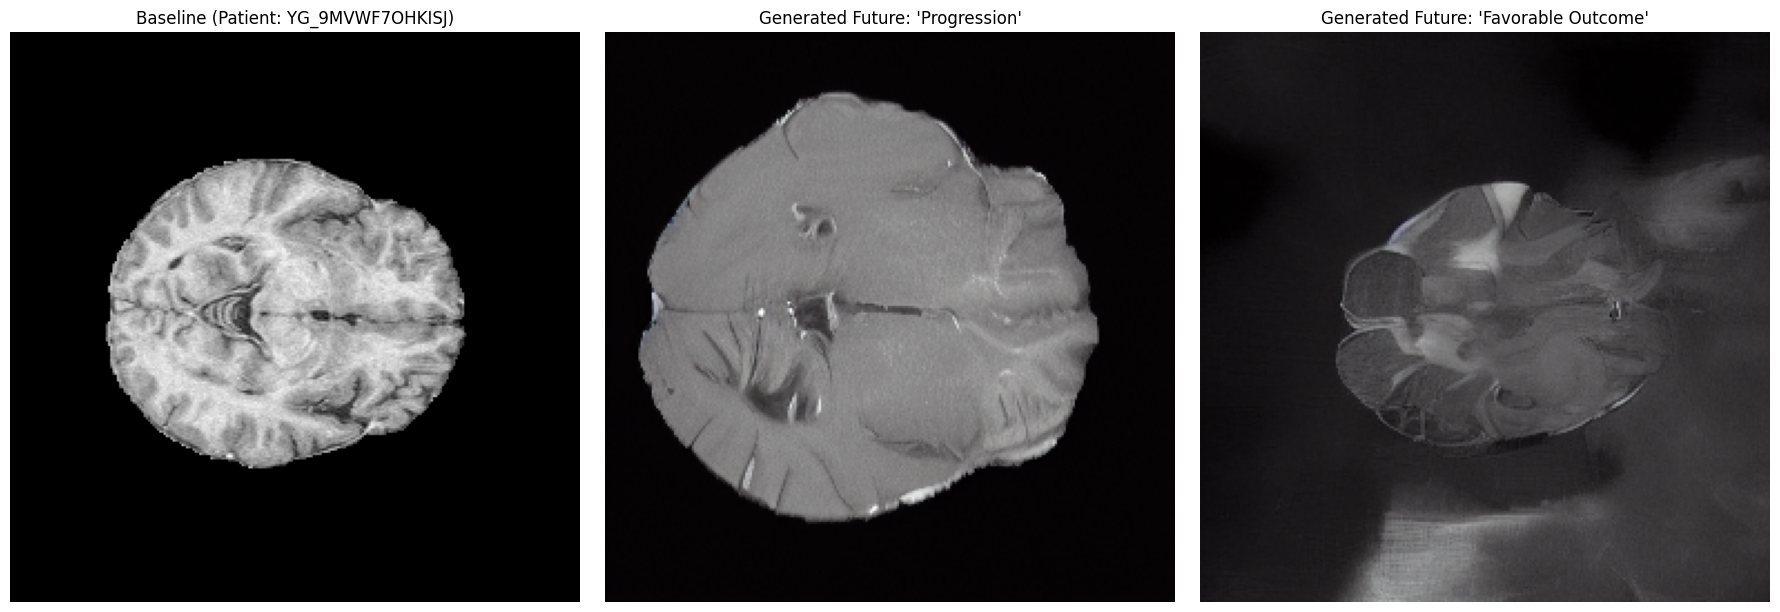


--- Processing sample 2/3 for patient: YG_YQ6AJRTYXFBP ---

Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]

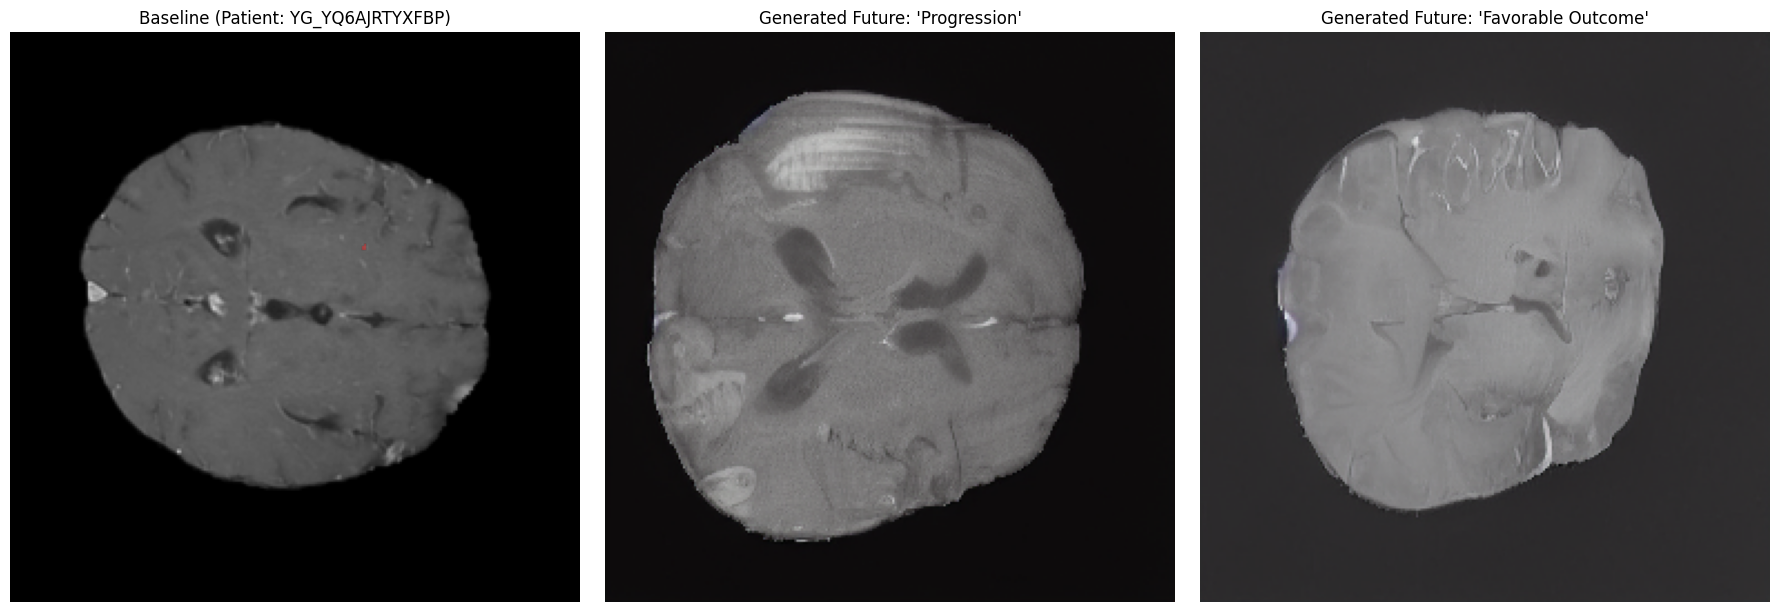


--- Processing sample 3/3 for patient: YG_8YUL10JGZV5U ---

Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]

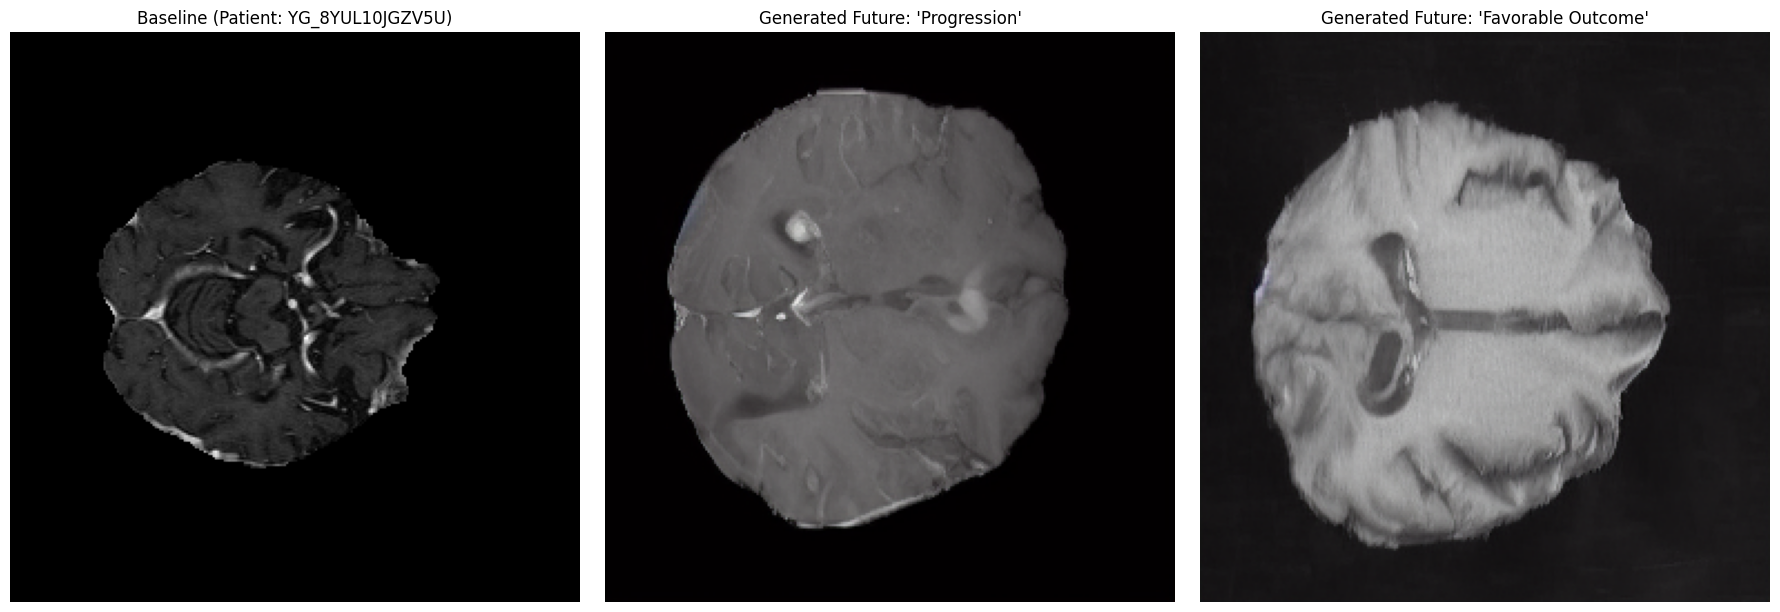

In [6]:
from tqdm.auto import tqdm
from PIL import Image
import numpy as np

# ===================================================================
# 推論（画像生成）を行う関数（変更なし）
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50):
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    with torch.no_grad():
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    model.scheduler.set_timesteps(num_inference_steps)
    latents = torch.randn_like(baseline_latents)

    for t in tqdm(model.scheduler.timesteps, desc="Denoising"):
        with torch.no_grad():
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    with torch.no_grad():
        latents = 1 / model.vae.config.scaling_factor * latents
        image = model.vae.decode(latents).sample
        
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# ===================================================================
# 複数の患者に対してループ処理で生成と可視化を行う
# ===================================================================
NUM_SAMPLES_TO_SHOW = 3 # 表示したい患者の人数

def to_pil(tensor_image):
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

# test_dataloaderから指定した人数分のデータを取得
for i, sample_batch in enumerate(test_dataloader):
    if i >= NUM_SAMPLES_TO_SHOW:
        break

    # --- データを準備 ---
    baseline_image = sample_batch["baseline_image"].to(device)
    patient_id = sample_batch["patient_id"][0]
    baseline_filename = sample_batch["filename"][0]
    print(f"\n--- Processing sample {i+1}/{NUM_SAMPLES_TO_SHOW} for patient: {patient_id} ---")

    # --- 2つの条件で画像を生成 ---
    progression_image = generate_future_image(model, baseline_image, "Progression")
    favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")
    
    # --- 対応するセグメンテーションマスクを読み込む ---
    SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
    seg_path = os.path.join(SEG_DIR, baseline_filename)
    seg_mask_rgba = None
    try:
        seg_nii = nib.load(seg_path)
        seg_data = seg_nii.get_fdata().astype('float32')
        seg_slice = seg_data[:, :, seg_data.shape[2] // 2]
        seg_slice_pil = Image.fromarray(seg_slice).resize((256, 256), Image.NEAREST)
        seg_mask = np.array(seg_slice_pil)
        seg_mask_rgba = np.zeros((256, 256, 4))
        seg_mask_rgba[seg_mask > 0] = [1, 0, 0, 0.4] # 赤色, 40%の透明度
    except FileNotFoundError:
        print(f"Warning: Segmentation mask not found at {seg_path}")
        
    # --- 結果を可視化 ---
    plt.figure(figsize=(18, 6))
    
    plt.subplot(1, 3, 1)
    plt.imshow(to_pil(baseline_image), cmap='gray')
    if seg_mask_rgba is not None:
        plt.imshow(seg_mask_rgba)
    plt.title(f"Baseline (Patient: {patient_id})")
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(progression_image, cmap='gray')
    plt.title("Generated Future: 'Progression'")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(favorable_image, cmap='gray')
    plt.title("Generated Future: 'Favorable Outcome'")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()